### Begin

In [1]:
# env1 3.11.13
import pandas as pd
from pathlib import Path
import requests
import pandas as pd
import numpy as np
import joblib
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt
import io
import zipfile




exports = Path("loadcurves/exports")

#### Weather

In [2]:
# PUMA COAST
# 2A HOT MOIST climate zone by IECC, see map
puma_coast_GID = pd.read_csv(exports / "tl_2018_48_puma10_COAST.csv")

In [3]:
# 1. Convert columns to strings and add leading zeros (padding)
# STATEFP10 needs 2 digits (e.g., 48)
state_str = puma_coast_GID['STATEFP10'].astype(str).str.zfill(2)

# PUMACE10 needs 5 digits (e.g., 00870)
puma_str = puma_coast_GID['PUMACE10'].astype(str).str.zfill(5)

# 2. Concatenate
gid_series = 'G' + state_str + puma_str

# 3. Convert to list
GID_list = gid_series.tolist()

# Verify
print(GID_list[:5])

['G4804501', 'G4804504', 'G4804625', 'G4804602', 'G4804618']


In [4]:
# in EST time zone, no daylight saving time observed

In [5]:
# 1. Define the base URL
base_url = "https://oedi-data-lake.s3.amazonaws.com/nrel-pds-building-stock/end-use-load-profiles-for-us-building-stock/2025/resstock_amy2018_release_1/weather/state=TX/"

# 2. List of file names to load
file_names = [f"{gid}_2018.csv" for gid in GID_list]

# 3. Load files and add the ID column
data_frames = []

for file_name in file_names:
    full_url = base_url + file_name
    
    # Extract the ID (the "G" part) by splitting at the underscore
    # "G4800870_2018.csv" -> ["G4800870", "2018.csv"] -> "G4800870"
    file_id = file_name.split('_')[0]
    
    print(f"Loading {file_name} (ID: {file_id})...")
    
    try:
        df = pd.read_csv(full_url)
        
        # Add the extracted ID as a new column
        df['location_id'] = file_id
        
        data_frames.append(df)
        
    except Exception as e:
        print(f"Error loading {file_name}: {e}")

# 4. Combine all into a single DataFrame (Optional)
if data_frames:
    all_data = pd.concat(data_frames, ignore_index=True)

Loading G4804501_2018.csv (ID: G4804501)...
Error loading G4804501_2018.csv: HTTP Error 404: Not Found
Loading G4804504_2018.csv (ID: G4804504)...
Error loading G4804504_2018.csv: HTTP Error 404: Not Found
Loading G4804625_2018.csv (ID: G4804625)...
Error loading G4804625_2018.csv: HTTP Error 404: Not Found
Loading G4804602_2018.csv (ID: G4804602)...
Error loading G4804602_2018.csv: HTTP Error 404: Not Found
Loading G4804618_2018.csv (ID: G4804618)...
Error loading G4804618_2018.csv: HTTP Error 404: Not Found
Loading G4804619_2018.csv (ID: G4804619)...
Error loading G4804619_2018.csv: HTTP Error 404: Not Found
Loading G4804901_2018.csv (ID: G4804901)...
Error loading G4804901_2018.csv: HTTP Error 404: Not Found
Loading G4804902_2018.csv (ID: G4804902)...
Error loading G4804902_2018.csv: HTTP Error 404: Not Found
Loading G4804903_2018.csv (ID: G4804903)...
Error loading G4804903_2018.csv: HTTP Error 404: Not Found
Loading G4804400_2018.csv (ID: G4804400)...
Error loading G4804400_2018.c

In [6]:
all_data.location_id.unique()

<StringArray>
['G4804610', 'G4804630']
Length: 2, dtype: str

In [7]:
weather = all_data.copy()
weather.to_csv(exports / "TX_PUMA_COAST_2018_weather.csv", index=False)

In [8]:
weather.head()

,date_time,Dry Bulb Temperature [°C],Relative Humidity [%],Wind Speed [m/s],Wind Direction [Deg],Global Horizontal Radiation [W/m2],Direct Normal Radiation [W/m2],Diffuse Horizontal Radiation [W/m2],location_id
0,2018-01-01 01:00:00,-7.20,69.04,4.27,43.33,0.0,0.0,0.0,G4804610
1,2018-01-01 02:00:00,-7.20,67.18,5.70,30.00,0.0,0.0,0.0,G4804610
2,2018-01-01 03:00:00,-7.80,61.24,5.70,50.00,0.0,0.0,0.0,G4804610
3,2018-01-01 04:00:00,-8.05,66.95,5.95,50.00,0.0,0.0,0.0,G4804610
4,2018-01-01 05:00:00,-9.40,60.31,6.70,40.00,0.0,0.0,0.0,G4804610


#### Load ERCOT

In [9]:
# from https://www.ercot.com/gridinfo/load/load_hist

# most likely in Central Time Zone (CT), needs conversion

ercot_native_2018 = pd.read_excel(exports / "Native_Load_2018.xlsx", sheet_name="Native Load Report")

In [10]:
ercot_native_2018.head()

,HourEnding,COAST,EAST,FWEST,NORTH,NCENT,SOUTH,SCENT,WEST,ERCOT
0,01/01/2018 01:00,11425.979115,1852.663959,2823.409245,1135.360907,18584.343617,3831.649454,9151.190703,1762.472684,50567.069682
1,01/01/2018 02:00,11408.418023,1850.169452,2809.745403,1136.630855,18524.141392,3988.271046,9144.993712,1754.718094,50617.087977
2,01/01/2018 03:00,11405.198365,1858.269586,2797.802576,1135.930264,18532.056616,4076.086451,9141.036615,1747.919615,50694.300087
3,01/01/2018 04:00,11450.560138,1879.623596,2807.793880,1146.069491,18647.444612,4154.939804,9157.956866,1755.203307,50999.591693
4,01/01/2018 05:00,11631.337459,1876.481320,2822.989206,1154.186967,19002.102222,4247.451523,9214.333628,1774.849690,51723.732017


#### NREL Comstock

In [11]:
# from https://data.openei.org/s3_viewer?bucket=oedi-data-lake&prefix=nrel-pds-building-stock%2Fend-use-load-profiles-for-us-building-stock%2F2025%2Fcomstock_amy2018_release_3%2Ftimeseries_aggregates%2Fby_ashrae_iecc_climate_zone_2006%2Fupgrade%3D0%2Fashrae_iecc_climate_zone_2006%3D2A%2F&limit=50

# 1. Setup for ComStock
zone_folder = "2A"  # Uppercase for Folder
zone_prefix = "2a"  # Lowercase for Filenames
output_dir = exports

In [12]:
# 2. ComStock Base URL (Note: Uses 'release_3' and 'climate_zone_2006')
base_url = (
    "https://oedi-data-lake.s3.amazonaws.com/"
    "nrel-pds-building-stock/end-use-load-profiles-for-us-building-stock/2025/"
    "comstock_amy2018_release_3/timeseries_aggregates/"
    "by_ashrae_iecc_climate_zone_2006/upgrade=0/"
    f"ashrae_iecc_climate_zone_2006={zone_folder}/"
)

# 3. Define the Commercial Building Types
# These match the filenames you provided (up0-2a-...)
building_types = [
    "fullservicerestaurant",
    "grocery",
    "hospital",
    "largehotel",
    "largeoffice",
    "mediumoffice",
    "outpatient",
    "primaryschool",
    "quickservicerestaurant",
    "retailstandalone",
    "retailstripmall",
    "secondaryschool",
    "smallhotel",
    "smalloffice",
    "warehouse"
]

# Generate the full filenames: "up0-2a-hospital.csv"
file_names = [f"up0-{zone_prefix}-{btype}.csv" for btype in building_types]

# 4. Download Loop
print(f"Starting Download for ComStock Zone {zone_folder}...")
print(f"Target URL Base: {base_url}")

for fname in file_names:
    full_url = base_url + fname
    save_path = exports / fname
    
    # Skip if already exists to save time/bandwidth
    if save_path.exists():
        print(f"Skipping {fname} (Already exists)")
        continue

    print(f"Fetching {fname}...")
    
    try:
        with requests.get(full_url, stream=True) as r:
            if r.status_code == 404:
                print(f" !! 404 Not Found: {fname} (Check URL or filename)")
                continue
            r.raise_for_status()
            
            with save_path.open('wb') as f:
                for chunk in r.iter_content(chunk_size=8192):
                    f.write(chunk)
                    
        print(f" -> Saved to {save_path.name}")
        
    except Exception as e:
        print(f"Error on {fname}: {e}")

print("-" * 30)
print("ComStock Download Complete.")

Starting Download for ComStock Zone 2A...
Target URL Base: https://oedi-data-lake.s3.amazonaws.com/nrel-pds-building-stock/end-use-load-profiles-for-us-building-stock/2025/comstock_amy2018_release_3/timeseries_aggregates/by_ashrae_iecc_climate_zone_2006/upgrade=0/ashrae_iecc_climate_zone_2006=2A/
Skipping up0-2a-fullservicerestaurant.csv (Already exists)
Skipping up0-2a-grocery.csv (Already exists)
Skipping up0-2a-hospital.csv (Already exists)
Skipping up0-2a-largehotel.csv (Already exists)
Skipping up0-2a-largeoffice.csv (Already exists)
Skipping up0-2a-mediumoffice.csv (Already exists)
Skipping up0-2a-outpatient.csv (Already exists)
Skipping up0-2a-primaryschool.csv (Already exists)
Skipping up0-2a-quickservicerestaurant.csv (Already exists)
Skipping up0-2a-retailstandalone.csv (Already exists)
Skipping up0-2a-retailstripmall.csv (Already exists)
Skipping up0-2a-secondaryschool.csv (Already exists)
Skipping up0-2a-smallhotel.csv (Already exists)
Skipping up0-2a-smalloffice.csv (Alrea

In [13]:
# 1. Define the EXACT ComStock building types (must match filenames)
building_types = [
    "fullservicerestaurant",
    "grocery",
    "hospital",
    "largehotel",
    "largeoffice",
    "mediumoffice",
    "outpatient",
    "primaryschool",
    "quickservicerestaurant",
    "retailstandalone",
    "retailstripmall",
    "secondaryschool",
    "smallhotel",
    "smalloffice",
    "warehouse"
]

# 2. Create the Dictionary
comstock_profiles = {}

print(f"Loading ComStock profiles from: {exports}")

for btype in building_types:
    # Reconstruct the exact filename pattern (Note: 'up0-' for ComStock)
    fname = f"up0-{zone_prefix}-{btype}.csv"
    file_path = exports / fname
    
    print(f"Reading {fname} ...")
    
    # Check if it actually exists before trying to read
    if file_path.exists():
        # Read the file
        df = pd.read_csv(file_path)
        
        # We use 'btype' as the key (e.g., 'hospital') for easier mapping later
        key = btype 
        comstock_profiles[key] = df
        
        print(f" -> Success! Loaded {len(df)} rows into key: '{key}'")
    else:
        print(f" -> WARNING: File not found at {file_path}")

print("-" * 40)
print(f"Loaded {len(comstock_profiles)} profiles.")
print("Example keys:", list(comstock_profiles.keys())[:3])

Loading ComStock profiles from: loadcurves/exports
Reading up0-2a-fullservicerestaurant.csv ...
 -> Success! Loaded 35040 rows into key: 'fullservicerestaurant'
Reading up0-2a-grocery.csv ...
 -> Success! Loaded 35040 rows into key: 'grocery'
Reading up0-2a-hospital.csv ...
 -> Success! Loaded 35040 rows into key: 'hospital'
Reading up0-2a-largehotel.csv ...
 -> Success! Loaded 35040 rows into key: 'largehotel'
Reading up0-2a-largeoffice.csv ...
 -> Success! Loaded 35040 rows into key: 'largeoffice'
Reading up0-2a-mediumoffice.csv ...
 -> Success! Loaded 35040 rows into key: 'mediumoffice'
Reading up0-2a-outpatient.csv ...
 -> Success! Loaded 35040 rows into key: 'outpatient'
Reading up0-2a-primaryschool.csv ...
 -> Success! Loaded 35040 rows into key: 'primaryschool'
Reading up0-2a-quickservicerestaurant.csv ...
 -> Success! Loaded 35040 rows into key: 'quickservicerestaurant'
Reading up0-2a-retailstandalone.csv ...
 -> Success! Loaded 35040 rows into key: 'retailstandalone'
Reading u

In [14]:
comstock_profiles['fullservicerestaurant'].head(4)

,upgrade,in.ashrae_iecc_climate_zone_2006,in.comstock_building_type,timestamp,models_used,floor_area_represented,out.district_cooling.cooling.energy_consumption.kwh,out.district_heating.heating.energy_consumption.kwh,out.district_heating.water_systems.energy_consumption.kwh,out.electricity.cooling.energy_consumption.kwh,...,out.propane.water_systems.energy_consumption.kwh,out.electricity.net.energy_consumption.kwh,out.electricity.purchased.energy_consumption.kwh,out.district_cooling.total.energy_consumption.kwh,out.district_heating.total.energy_consumption.kwh,out.electricity.total.energy_consumption.kwh,out.fuel_oil.total.energy_consumption.kwh,out.natural_gas.total.energy_consumption.kwh,out.propane.total.energy_consumption.kwh,out.site_energy.total.energy_consumption.kwh
0,0,2A,FullServiceRestaurant,2018-01-01 00:15:00,412,1.194437e+08,253.45557,241.93393,160.11867,1978.7328,...,2643.7014,124395.450,124395.450,253.45557,402.05258,124395.450,0.0,53948.977,6221.6577,185221.72
1,0,2A,FullServiceRestaurant,2018-01-01 00:30:00,412,1.194437e+08,265.63864,289.30570,151.26295,1900.8011,...,2566.1587,118952.445,118952.445,265.63864,440.56863,118952.445,0.0,54311.130,6166.1280,180135.89
2,0,2A,FullServiceRestaurant,2018-01-01 00:45:00,412,1.194437e+08,262.19010,272.45650,148.80156,2050.2670,...,2539.8435,114871.010,114871.010,262.19010,421.25803,114871.010,0.0,54121.438,6228.6290,175904.50
3,0,2A,FullServiceRestaurant,2018-01-01 01:00:00,412,1.194437e+08,282.43660,294.94660,146.72331,2262.5603,...,2446.6306,113734.980,113734.980,282.43660,441.66990,113734.980,0.0,54077.477,6205.7640,174742.20


In [15]:
comstock_profiles['fullservicerestaurant']["out.electricity.total.energy_consumption.kwh"].head(4)

0    124395.450
1    118952.445
2    114871.010
3    113734.980
Name: out.electricity.total.energy_consumption.kwh, dtype: float64

In [16]:
def aggregate_to_hourly_per_sqft(df_15min, target_col):
    """
    Aggregates 15-min to Hourly (Hour Ending), removes initialization row,
    and DIVIDES by 'floor_area_represented' to get Load per SqFt.
    """
    # Create a copy to avoid SettingWithCopy warnings on the original df
    df = df_15min.copy()

    # 1. Set Index if needed
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        df = df.set_index('timestamp')
    elif 'date_time' in df.columns:
        df['date_time'] = pd.to_datetime(df['date_time'])
        df = df.set_index('date_time')
    
    # 2. Get the Total Area (Scalar)
    # ComStock files contain the TOTAL sqft of all buildings represented in the file.
    # We grab the first value (it is constant).
    if 'floor_area_represented' in df.columns:
        total_sqft = df['floor_area_represented'].iloc[0]
    else:
        print(f"Warning: 'floor_area_represented' not found. Keeping raw values.")
        total_sqft = 1.0
        
    # Safety check for zero to prevent division errors
    if total_sqft == 0:
        total_sqft = 1.0

    # 3. Resample to Hourly SUM
    # The source data is 15-min Energy (kWh). 
    # Summing 4 intervals = Total kWh for that hour = Average kW for that hour.
    # label='right', closed='right' ensures 00:15, 00:30, 00:45, 01:00 sums to Hour 01
    df_hourly = df[[target_col]].resample('h', label='right', closed='right').sum()
    
    # 4. Clean up: Drop the 2018-01-01 00:00:00 initialization row (ResStock/ComStock artifact)
    if not df_hourly.empty:
        # Check if the first index is midnight exactly (start of year)
        if df_hourly.index[0].hour == 0 and df_hourly.index[0].minute == 0:
            df_hourly = df_hourly.iloc[1:]
        
    # 5. NORMALIZE (The Fix)
    # Convert "Total Load of 10 million sqft" -> "Load per 1 sqft"
    df_hourly[target_col] = df_hourly[target_col] / total_sqft
    
    return df_hourly

In [17]:
# --- CONFIGURATION ---
target_col = 'out.electricity.total.energy_consumption.kwh'
hourly_profiles = {}

print(f"Aggregating ComStock Profiles using predefined function...")

for b_type, df_15 in comstock_profiles.items():
    try:
        # The function handles index setting, resampling, and 'floor_area_represented' normalization
        df_hourly = aggregate_to_hourly_per_sqft(df_15, target_col)
        
        # Store result
        hourly_profiles[b_type] = df_hourly
        
        # Print first value to verify normalization happened (should be small, e.g., 0.001)
        val = df_hourly[target_col].iloc[0]
        print(f" -> {b_type}: Done. ({val:.6f} kWh/sqft)")
        
    except Exception as e:
        print(f" !! Error processing {b_type}: {e}")

print("-" * 40)
print("Processing Complete.")

Aggregating ComStock Profiles using predefined function...
 -> fullservicerestaurant: Done. (0.003951 kWh/sqft)
 -> grocery: Done. (0.004970 kWh/sqft)
 -> hospital: Done. (0.001828 kWh/sqft)
 -> largehotel: Done. (0.001520 kWh/sqft)
 -> largeoffice: Done. (0.001071 kWh/sqft)
 -> mediumoffice: Done. (0.001180 kWh/sqft)
 -> outpatient: Done. (0.001391 kWh/sqft)
 -> primaryschool: Done. (0.001000 kWh/sqft)
 -> quickservicerestaurant: Done. (0.003635 kWh/sqft)
 -> retailstandalone: Done. (0.001022 kWh/sqft)
 -> retailstripmall: Done. (0.001661 kWh/sqft)
 -> secondaryschool: Done. (0.000564 kWh/sqft)
 -> smallhotel: Done. (0.001939 kWh/sqft)
 -> smalloffice: Done. (0.001291 kWh/sqft)
 -> warehouse: Done. (0.000635 kWh/sqft)
----------------------------------------
Processing Complete.


In [18]:
# Define the export path
profiles_csv_path = exports / "COMSTOCK_normalized_hourly_profiles.csv"

# ==========================================
# 1. SAVE THE DICT TO A SINGLE CSV
# ==========================================
print("Consolidating and saving profiles...")

# Get the datetime index from the first available profile to use as our base
first_key = list(hourly_profiles.keys())[0]
combined_profiles_df = pd.DataFrame(index=hourly_profiles[first_key].index)

# Loop through the dictionary and add each building's column to the combined DataFrame
for b_type, df in hourly_profiles.items():
    # We pull the single column of data and name it the building type
    combined_profiles_df[b_type] = df[target_col]

# Save to disk
combined_profiles_df.to_csv(profiles_csv_path)
print(f" -> Saved all profiles to: {profiles_csv_path}")

Consolidating and saving profiles...
 -> Saved all profiles to: loadcurves/exports/COMSTOCK_normalized_hourly_profiles.csv


#### ML models for each building type

In [19]:
weather = pd.read_csv(exports / "TX_PUMA_COAST_2018_weather.csv")

In [20]:
weather.head(2)

,date_time,Dry Bulb Temperature [°C],Relative Humidity [%],Wind Speed [m/s],Wind Direction [Deg],Global Horizontal Radiation [W/m2],Direct Normal Radiation [W/m2],Diffuse Horizontal Radiation [W/m2],location_id
0,2018-01-01 01:00:00,-7.2,69.04,4.27,43.33,0.0,0.0,0.0,G4804610
1,2018-01-01 02:00:00,-7.2,67.18,5.70,30.00,0.0,0.0,0.0,G4804610


In [21]:
print("\nReading profiles back into a dictionary...")


profiles_csv_path = exports / "COMSTOCK_normalized_hourly_profiles.csv"

# Read the CSV. 
# CRITICAL: index_col=0 keeps the timestamp as the index, parse_dates=True converts it back to datetime objects
loaded_combined_df = pd.read_csv(profiles_csv_path, index_col=0, parse_dates=True)

hourly_profiles_loaded = {}

# Reconstruct the dictionary
for b_type in loaded_combined_df.columns:
    # 1. Extract the column as its own DataFrame
    df_single = loaded_combined_df[[b_type]].copy()
    
    # 2. Rename the column back to the original target_col name ('out.electricity.total...kwh')
    # This ensures it matches exactly what your downstream code expects
    df_single = df_single.rename(columns={b_type: target_col})
    
    # 3. Store it in the new dict
    hourly_profiles_loaded[b_type] = df_single

print(f" -> Successfully reconstructed dict with {len(hourly_profiles_loaded)} building types.")


Reading profiles back into a dictionary...
 -> Successfully reconstructed dict with 15 building types.


In [22]:
# --- 1. PREPARE WEATHER DATA (X) ---

# Select just one location (since they are identical)
location_id = 'G4804610'
weather_clean = weather[weather['location_id'] == location_id].copy()

# Convert timestamp and sort
weather_clean['date_time'] = pd.to_datetime(weather_clean['date_time'])
weather_clean = weather_clean.sort_values('date_time').reset_index(drop=True)

# Feature Engineering: Add Time Features
# These are critical because people behave differently at 2 AM vs 2 PM, and on Sundays vs Mondays.
weather_clean['hour'] = weather_clean['date_time'].dt.hour
weather_clean['month'] = weather_clean['date_time'].dt.month
weather_clean['day_of_week'] = weather_clean['date_time'].dt.dayofweek  # 0=Monday, 6=Sunday

# Define Feature Columns
feature_cols = [
    'Dry Bulb Temperature [°C]', 
    'Relative Humidity [%]',
    'Wind Speed [m/s]', 
    'Global Horizontal Radiation [W/m2]', 
    'hour', 
    'month', 
    'day_of_week'
]

X = weather_clean[feature_cols]

print(f"Feature Matrix Shape: {X.shape}")
print(f"Features used: {feature_cols}")
print("-" * 30)

Feature Matrix Shape: (8760, 7)
Features used: ['Dry Bulb Temperature [°C]', 'Relative Humidity [%]', 'Wind Speed [m/s]', 'Global Horizontal Radiation [W/m2]', 'hour', 'month', 'day_of_week']
------------------------------


In [23]:
# --- 1. SETUP DIRECTORIES ---
# Create folders if they don't exist (added _comstock to prevent overwriting resstock)
models_dir = Path("models_comstock")
models_dir.mkdir(exist_ok=True)

metrics_dir = Path("metrics_comstock")
metrics_dir.mkdir(exist_ok=True)

print(f"Directories ready: '{models_dir}' and '{metrics_dir}'")

# --- 2. TRAIN LOOP ---

target_col = 'out.electricity.total.energy_consumption.kwh'
models = {}
results_list = []  # List to collect rows for the final CSV

print("Training Random Forest models using ComStock Hourly Profiles...")

# Use the dict we loaded in the previous step
for b_type, df_hourly in hourly_profiles_loaded.items():
    print(f"\nProcessing: {b_type}")
    
    # -- Data Prep --
    y = df_hourly[target_col].values
    
    if len(X) != len(y):
        print(f"!! Mismatch Error: Weather (X) has {len(X)} rows, Profile (y) has {len(y)} rows.")
        continue

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # -- Training --
    rf = RandomForestRegressor(n_estimators=100, max_depth=20, random_state=42, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    # -- Evaluation --
    preds = rf.predict(X_test)
    score = r2_score(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    
    print(f" -> Done. R^2 Score: {score:.4f} | RMSE: {rmse:.4f} kWh")
    
    # -- SAVE MODEL --
    # Sanitize filename (replace spaces or special chars if any)
    safe_name = str(b_type).replace(" ", "_").replace("/", "-")
    model_path = models_dir / f"rf_model_{safe_name}.joblib"
    
    joblib.dump(rf, model_path)
    print(f"    Saved model to: {model_path}")
    
    # -- COLLECT METRICS --
    # Store in memory to create the CSV at the end
    models[b_type] = rf
    results_list.append({
        'Building_Type': b_type,
        'R2_Score': score,
        'RMSE_kWh': rmse,
        'Model_Path': str(model_path)
    })

# --- 3. SAVE METRICS CSV ---
metrics_df = pd.DataFrame(results_list)
metrics_path = metrics_dir / "comstock_training_metrics.csv"
metrics_df.to_csv(metrics_path, index=False)

print("\n" + "="*30)
print(f"All operations complete.")
print(f"Metrics saved to: {metrics_path}")

Directories ready: 'models_comstock' and 'metrics_comstock'
Training Random Forest models using ComStock Hourly Profiles...

Processing: fullservicerestaurant
 -> Done. R^2 Score: 0.9820 | RMSE: 0.0005 kWh
    Saved model to: models_comstock/rf_model_fullservicerestaurant.joblib

Processing: grocery
 -> Done. R^2 Score: 0.9658 | RMSE: 0.0002 kWh
    Saved model to: models_comstock/rf_model_grocery.joblib

Processing: hospital
 -> Done. R^2 Score: 0.9721 | RMSE: 0.0001 kWh
    Saved model to: models_comstock/rf_model_hospital.joblib

Processing: largehotel
 -> Done. R^2 Score: 0.9583 | RMSE: 0.0001 kWh
    Saved model to: models_comstock/rf_model_largehotel.joblib

Processing: largeoffice
 -> Done. R^2 Score: 0.9705 | RMSE: 0.0001 kWh
    Saved model to: models_comstock/rf_model_largeoffice.joblib

Processing: mediumoffice
 -> Done. R^2 Score: 0.9721 | RMSE: 0.0001 kWh
    Saved model to: models_comstock/rf_model_mediumoffice.joblib

Processing: outpatient
 -> Done. R^2 Score: 0.9783 | 

Calculating Feature Importances across all building types...

--- AVERAGE FEATURE IMPORTANCE (All Buildings) ---
Global Horizontal Radiation [W/m2]    46.6%
hour                                  19.7%
Dry Bulb Temperature [°C]             14.7%
day_of_week                           10.4%
month                                  5.7%
Relative Humidity [%]                  2.1%
Wind Speed [m/s]                       0.8%
dtype: str

--- TOP DRIVER PER BUILDING ---
fullservicerestaurant     : Global Horizontal Radiation [W/m2]
grocery                   : hour
hospital                  : Global Horizontal Radiation [W/m2]
largehotel                : hour
largeoffice               : Global Horizontal Radiation [W/m2]
mediumoffice              : Global Horizontal Radiation [W/m2]
outpatient                : Global Horizontal Radiation [W/m2]
primaryschool             : Global Horizontal Radiation [W/m2]
quickservicerestaurant    : Global Horizontal Radiation [W/m2]
retailstandalone          : 

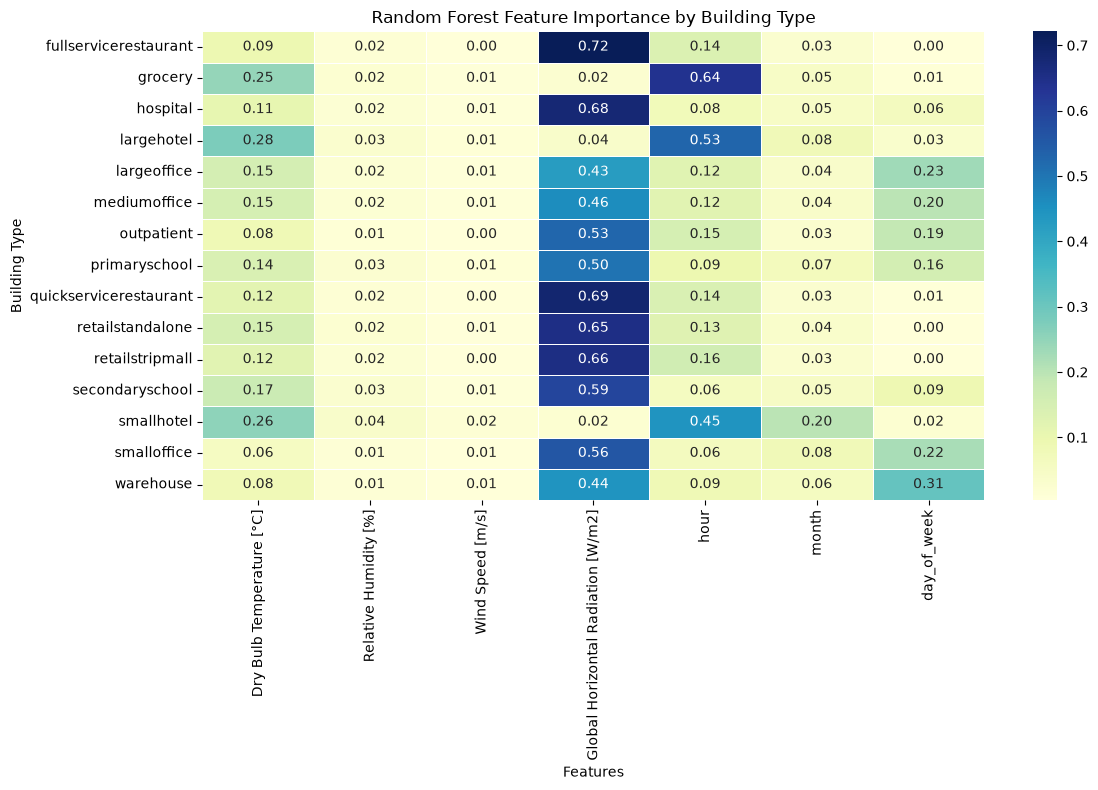

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Calculating Feature Importances across all building types...")

# 1. Extract importances into a dictionary
importance_dict = {}

for b_type, model in models.items():
    # Random Forest stores importances in this attribute after fitting
    importance_dict[b_type] = model.feature_importances_

# 2. Create a DataFrame
# Rows = Building Types, Columns = Features
df_importance = pd.DataFrame.from_dict(importance_dict, orient='index', columns=feature_cols)

# 3. Display the text table (sorted by what drives the average building the most)
mean_importance = df_importance.mean().sort_values(ascending=False)
print("\n--- AVERAGE FEATURE IMPORTANCE (All Buildings) ---")
print(mean_importance.apply(lambda x: f"{x:.1%}"))

print("\n--- TOP DRIVER PER BUILDING ---")
top_drivers = df_importance.idxmax(axis=1)
for b_type, driver in top_drivers.items():
    print(f"{b_type.ljust(25)} : {driver}")

# 4. Plot a Heatmap for visual comparison
plt.figure(figsize=(12, 8))
sns.heatmap(df_importance, annot=True, cmap="YlGnBu", fmt=".2f", linewidths=.5)
plt.title("Random Forest Feature Importance by Building Type")
plt.xlabel("Features")
plt.ylabel("Building Type")
plt.tight_layout()
plt.show()

#### Estimate SQFT of commercial buildings in area using County Business Patterns

In [25]:
YEAR = "2018"
STATE_PREFIXES = ("75", "76", "77", "78", "79", "885") 

ZBP_URL = f"https://www2.census.gov/programs-surveys/cbp/datasets/{YEAR}/zbp{YEAR[-2:]}detail.zip"
CSV_NAME = f"zbp{YEAR[-2:]}detail.txt"

# Ensure the directory exists
exports.mkdir(parents=True, exist_ok=True)

print(f"1. Downloading ZBP {YEAR} Detail File (~60MB compressed)...")
r = requests.get(ZBP_URL)

if r.status_code == 200:
    print("2. Extracting and Loading Data...")
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        with z.open(CSV_NAME) as f:
            # Load data. Force zip/naics to string to keep leading zeros.
            df = pd.read_csv(f, dtype={'zip': str, 'naics': str})
            
    print(f"3. Filtering for Texas ZIPs (Prefixes: {STATE_PREFIXES})...")
    df.columns = [c.lower() for c in df.columns]
    
    # Filter for Texas
    df_tx = df[df['zip'].str.startswith(STATE_PREFIXES, na=False)].copy()
    
    print("4. Calculating Estimated Employment...")
    
    # Define the midpoint for each bin
    size_map = {
        'n<5': 2.5,       'n5_9': 7.0,      'n10_19': 14.5,
        'n20_49': 34.5,   'n50_99': 74.5,   'n100_249': 174.5,
        'n250_499': 374.5,'n500_999': 749.5,'n1000': 1500.0
    }
    
    df_tx['EMP_Calculated'] = 0.0
    
    # Loop through columns and add to total
    for col, multiplier in size_map.items():
        if col in df_tx.columns:
            # 1. Convert to numeric (coercing errors to NaN)
            # 2. Fill NaNs with 0
            val = pd.to_numeric(df_tx[col], errors='coerce').fillna(0)
            df_tx['EMP_Calculated'] += val * multiplier

    # Round to integer
    df_tx['Final_Employees'] = df_tx['EMP_Calculated'].round(0).astype(int)

    # 5. Save
    output_path = exports / f"tx_zbp_{YEAR}_commercial_raw.csv"
    
    # We drop 'emp' from this list since it doesn't exist
    cols_to_keep = ['zip', 'naics', 'est', 'Final_Employees']
    
    # Check if 'est' exists (it usually does), if not, skip it
    actual_cols = [c for c in cols_to_keep if c in df_tx.columns]
    final_df = df_tx[actual_cols]
    
    final_df.to_csv(output_path, index=False)
    
    print("-" * 40)
    print(f"Success! Saved {len(final_df)} rows to:")
    print(output_path)
    print("-" * 40)
    print(final_df.head())

else:
    print(f"Error: Could not download file. Status: {r.status_code}")

1. Downloading ZBP 2018 Detail File (~60MB compressed)...
2. Extracting and Loading Data...
3. Filtering for Texas ZIPs (Prefixes: ('75', '76', '77', '78', '79', '885'))...
4. Calculating Estimated Employment...
----------------------------------------
Success! Saved 214462 rows to:
loadcurves/exports/tx_zbp_2018_commercial_raw.csv
----------------------------------------
           zip   naics   est  Final_Employees
2020050  75001  ------  1659            43704
2020051  75001  21----    14              126
2020052  75001  211///     9               18
2020053  75001  2111//     9               18
2020054  75001  21112/     6               12


In [26]:
print(f"Original Row Count: {len(final_df)}")

# Filter: Keep rows where 'naics' does NOT contain '-' or '/'
# This keeps only the detailed 6-digit industry codes
df_clean = final_df[~final_df['naics'].str.contains('[-/]')].copy()

print(f"Cleaned Row Count (6-digit only): {len(df_clean)}")

Original Row Count: 214462
Cleaned Row Count (6-digit only): 55526


In [27]:
# read ZCTA export from ArcGIS for the COAST region
zcta_coast = pd.read_csv(exports / "tl_2018_us_zcta510_COAST_centwithin.csv")
zcta_coast.head()

,ZCTA5CE10,GEOID10,CLASSFP10,MTFCC10,FUNCSTAT10,ALAND10,AWATER10,INTPTLAT10,INTPTLON10,Shape_Length,Shape_Area
0,77362,77362,B5,G6350,S,21379551.0,32665.0,30.160534,-95.669154,0.458074,0.002005
1,77365,77365,B5,G6350,S,91748592.0,1334888.0,30.110343,-95.268693,0.597380,0.008712
2,77372,77372,B5,G6350,S,134260515.0,479738.0,30.241145,-95.160299,0.765225,0.012628
3,77373,77373,B5,G6350,S,61496954.0,905145.0,30.062169,-95.383966,0.430581,0.005838
4,77375,77375,B5,G6350,S,88545174.0,1075581.0,30.094886,-95.585830,0.641220,0.008387


In [28]:
df_clean = df_clean.copy()

# B. CONVERT TYPES
# ZIPs: Keep as String to protect leading zeros
df_clean['zip'] = df_clean['zip'].astype(str)

# NAICS: Convert to Int for fast math processing
df_clean['naics'] = df_clean['naics'].astype(int)

# Employees: Convert to Int
df_clean['Final_Employees'] = pd.to_numeric(df_clean['Final_Employees']).fillna(0).astype(int)

# --- 2. SPATIAL FILTER (String Match) ---
# zcta_coast is your shapefile data. Ensure its ZIP column is also string.
meaningful_zips = zcta_coast['ZCTA5CE10'].astype(str).tolist()

df_coast_load = df_clean[df_clean['zip'].isin(meaningful_zips)].copy()

In [29]:
# Assuming df_coast_load is already created and filtered by ZIP
# and 'naics' is already converted to int

# 1. Get Unique Codes and their Employee Counts
# This is better than just a list because it tells you the "weight" of each code
naics_stats = df_coast_load.groupby('naics')['Final_Employees'].sum().sort_values(ascending=False)

print(f"Total Unique NAICS Codes: {len(naics_stats)}")
print("-" * 40)
print("Top 20 NAICS Codes by Employee Count:")
print(naics_stats.head(20))

Total Unique NAICS Codes: 524
----------------------------------------
Top 20 NAICS Codes by Employee Count:
naics
722513    107959
722511    105472
551114     55830
621111     33910
541330     24015
541110     21607
621210     17099
624410     16647
561320     16215
621610     15858
813110     15567
522110     13798
445110     13042
441110     12184
447110     11082
721110     10183
448140      9338
722515      9244
238220      9053
622110      9000
Name: Final_Employees, dtype: int64


In [30]:
def get_comstock_type(code):
    """
    Maps NAICS to ComStock Types.
    Separates 'Industrial' (Oil/Gas, Mfg) from Commercial.
    """
    
    # --- LEVEL 1: SPECIFIC COMMERCIAL OVERRIDES ---
    # Daycare (624410) -> Primary School (Best proxy for density/schedule)
    if code == 624410: return 'primaryschool'
    # Gyms (713940) -> Retail Standalone (High lighting/AC, open floor)
    if code == 713940: return 'retailstandalone'
    
    # Food Specifics
    if code == 445110: return 'grocery'
    if code == 722511: return 'fullservicerestaurant'
    if code == 722513: return 'quickservicerestaurant'
    if code == 722515: return 'quickservicerestaurant'

    # --- LEVEL 2: INDUSTRIAL / NON-COMMERCIAL ---
    # Sector 21: Mining, Quarrying, and Oil and Gas Extraction
    if code // 10000 == 21: return 'Industrial'
    
    # Sector 31-33: Manufacturing
    if code // 10000 in [31, 32, 33]: return 'Industrial'
    
    # Sector 11: Agriculture / Forestry / Fishing
    if code // 10000 == 11: return 'Industrial'
    
    # Sector 22: Utilities (Power plants, distribution centers)
    # Note: Utility HQs are offices, but operational sites are Industrial.
    # Given '221122' (Distribution) appeared, let's flag as Industrial to be safe.
    if code // 10000 == 22: return 'Industrial'

    # --- LEVEL 3: STANDARD COMMERCIAL MAPPINGS ---
    prefix_4 = code // 100
    prefix_3 = code // 1000
    prefix_2 = code // 10000
    
    # Lodging
    if prefix_4 == 7211: return 'largehotel'
    if prefix_4 == 7212: return 'smallhotel'
    
    # Education
    if prefix_4 == 6111: return 'primaryschool'
    if prefix_4 == 6112: return 'secondaryschool'
    if prefix_4 == 6113: return 'secondaryschool'
    
    # Health
    if prefix_3 == 622: return 'hospital'
    if prefix_3 == 621: return 'outpatient' # Offices of Physicians
    if prefix_3 == 623: return 'outpatient' # Nursing Homes
    if prefix_3 == 624: return 'outpatient' # Social Assistance
    
    # Food Service General
    if prefix_3 == 722: return 'fullservicerestaurant'
    
    # Office (Information, Finance, Real Estate, Prof. Services, Admin, Public Admin)
    if prefix_2 in [51, 52, 53, 54, 55, 56, 92]:
        return 'mediumoffice'
        
    # Retail (Retail Trade + Arts/Entertainment/Rec)
    if prefix_2 in [44, 45, 71]:
        return 'retailstandalone'
        
    # Warehousing (Wholesale, Transport)
    if prefix_2 in [42, 48, 49]:
        return 'warehouse'
        
    # Other Services (Repair, Personal, Religious)
    if prefix_2 == 81:
        return 'smalloffice'
        
    # Construction (Offices usually)
    if prefix_2 == 23:
        return 'smalloffice'

    return 'Other'

# --- APPLY ---
print("Applying Mapping (Separating Industrial)...")
df_coast_load['ComStock_Type'] = df_coast_load['naics'].apply(get_comstock_type)

# --- SPLIT THE DATA ---
# 1. Commercial Data (Ready for ComStock)
df_commercial = df_coast_load[
    (df_coast_load['ComStock_Type'] != 'Industrial') & 
    (df_coast_load['ComStock_Type'] != 'Other')
].copy()

# 2. Industrial Data (Save for later)
df_industrial = df_coast_load[df_coast_load['ComStock_Type'] == 'Industrial'].copy()

# --- REPORT ---
print("-" * 40)
print(f"Commercial Employees: {df_commercial['Final_Employees'].sum():,.0f} (Mapped to {df_commercial['ComStock_Type'].nunique()} models)")
print(f"Industrial Employees: {df_industrial['Final_Employees'].sum():,.0f} (Set aside)")
print("-" * 40)
print("Breakdown of Commercial Types:")
print(df_commercial.groupby('ComStock_Type')['Final_Employees'].sum().sort_values(ascending=False))

Applying Mapping (Separating Industrial)...
----------------------------------------
Commercial Employees: 773,029 (Mapped to 13 models)
Industrial Employees: 24,790 (Set aside)
----------------------------------------
Breakdown of Commercial Types:
ComStock_Type
mediumoffice              226767
quickservicerestaurant    117203
fullservicerestaurant     112008
outpatient                 81892
retailstandalone           81218
smalloffice                65277
warehouse                  35442
primaryschool              20463
grocery                    13042
largehotel                 10183
hospital                    9524
smallhotel                    10
secondaryschool                0
Name: Final_Employees, dtype: int64


In [31]:
df_commercial

,zip,naics,est,Final_Employees,ComStock_Type
2103325,77002,236115,3,0,smalloffice
2103326,77002,236118,3,0,smalloffice
2103329,77002,236220,4,0,smalloffice
2103335,77002,238210,3,0,smalloffice
2103337,77002,238220,4,0,smalloffice
...,...,...,...,...,...
2161130,77982,721110,4,0,largehotel
2161134,77982,722511,4,0,fullservicerestaurant
2161139,77982,811490,4,8,smalloffice
2161154,77983,721110,3,8,largehotel


In [32]:
# 1. Check how many rows have 0 employees (just for info)
zero_emp_count = len(df_commercial[df_commercial['Final_Employees'] == 0])
print(f"Dropping {zero_emp_count} rows with 0 employees...")

# 2. Filter: Keep only rows with positive employees
df_commercial = df_commercial[df_commercial['Final_Employees'] > 0].copy()

# 3. Final Check
print(f"Remaining Commercial Rows: {len(df_commercial)}")
print(df_commercial.head())

Dropping 4644 rows with 0 employees...
Remaining Commercial Rows: 8302
           zip   naics  est  Final_Employees ComStock_Type
2103353  77002  423420   16               32     warehouse
2103356  77002  423610    4               10     warehouse
2103359  77002  423830    4                8     warehouse
2103366  77002  424720   19              172     warehouse
2103370  77002  425120    5               21     warehouse


In [33]:
# Refined SqFt per Employee Dictionary
# Source: Hybrid of CBECS (Workers) & NREL Table 4 (Occupant Density adjusted for Staffing Ratios)
# https://www.eia.gov/consumption/commercial/data/2018/bc/pdf/b1.pdf
# https://www.eia.gov/consumption/commercial/data/2018/index.php?view=characteristics
# https://docs.nlr.gov/docs/fy11osti/46861.pdf#page=12.10 TABLE 4

sqft_per_emp = {
    # --- FOOD (Table 4: 15 sqft/diner -> ~300 sqft/staff) ---
    'quickservicerestaurant': 300,  # High density kitchen + high turnover
    'fullservicerestaurant': 400,   # (Lowered from 500)
    
    # --- RETAIL (Table 4: 67-125 sqft/shopper -> ~700-800 sqft/staff) ---
    'grocery': 750,                 # (Lowered from 1000 based on Table 4 "125")
    'retailstandalone': 800,        # General retail (Clothing, etc.)
    'retailstripmall': 700,         # Denser shops
    
    # --- HEALTH (Table 4: Mix of 50 (Clinic) and 200 (Rooms)) ---
    'hospital': 700,                # (Lowered from 800 - weighted avg of dense ER vs roomy wards)
    'outpatient': 500,              # Matches Table 4 "Exam Room" density + waiting areas
    
    # --- LODGING (Staff are sparse relative to rooms) ---
    'largehotel': 1500,             # Maids clean 15+ rooms/day -> Huge area per staff
    'smallhotel': 1200,             
    
    # --- EDUCATION (Table 4: 43 sqft/student * 25 students/teacher = ~1100) ---
    'primaryschool': 1100,          
    'secondaryschool': 1300,        # Includes stadiums/auditoriums (Table 4: "Auditorium 10.8")
    
    # --- OFFICE (Direct Match to Table 4) ---
    'largeoffice': 200,             # (Tightened from 250 to match Table 4 "200")
    'mediumoffice': 200,            
    'smalloffice': 200,             
    
    # --- INDUSTRIAL ---
    'warehouse': 3000               # Table 4 "Warehouse: 0.0" confirms very low occupancy
}

In [34]:
# List of all 15 expected ComStock types
all_comstock_types = [
    'smalloffice', 'mediumoffice', 'largeoffice',
    'retailstandalone', 'retailstripmall', 'grocery',
    'primaryschool', 'secondaryschool',
    'outpatient', 'hospital',
    'smallhotel', 'largehotel',
    'quickservicerestaurant', 'fullservicerestaurant',
    'warehouse'
]

# 1. Update Map
df_commercial['SqFt_Factor'] = df_commercial['ComStock_Type'].map(sqft_per_emp)
df_commercial['SqFt_Factor'] = df_commercial['SqFt_Factor'].fillna(250) # Fallback

# 2. Recalculate SqFt
df_commercial['Total_SqFt'] = df_commercial['Final_Employees'] * df_commercial['SqFt_Factor']

# 3. Re-Pivot
pivot_sqft = df_commercial.pivot_table(
    index='zip',
    columns='ComStock_Type',
    values='Total_SqFt',
    aggfunc='sum',
    fill_value=0
)

# 4. Enforce All Columns (The Fix)
# This adds any missing columns as 0.0 and sorts them consistently
pivot_sqft = pivot_sqft.reindex(columns=all_comstock_types, fill_value=0)

print(f"Recalculated SqFt with NREL-Adjusted Factors.")
print(f"Total Commercial SqFt in Region: {pivot_sqft.values.sum() / 1e6:,.2f} Million SqFt")
print(f"Columns present: {len(pivot_sqft.columns)} (Should be 15)")

Recalculated SqFt with NREL-Adjusted Factors.
Total Commercial SqFt in Region: 404.86 Million SqFt
Columns present: 15 (Should be 15)


In [35]:
pivot_sqft.head(4)

ComStock_Type,smalloffice,mediumoffice,largeoffice,retailstandalone,retailstripmall,grocery,primaryschool,secondaryschool,outpatient,hospital,smallhotel,largehotel,quickservicerestaurant,fullservicerestaurant,warehouse
zip,,,,,,,,,,,,,,,
77002,163600,6342800,0,639200,0,0,114400,0,239500,0,0,1041000,496200,1227200,915000
77003,7200,9200,0,46400,0,0,0,0,9000,0,0,0,62400,302400,336000
77004,61600,95000,0,36800,0,13500,56100,0,430500,0,0,27000,180600,106400,0
77005,166200,185000,0,460800,0,0,48400,0,249000,0,0,0,398400,412400,54000


In [36]:
zcta_to_bus_mapping = pd.read_csv(exports / "zcta_to_bus_mapping.csv")
zcta_to_bus_mapping.head()

,Join_Count,TARGET_FID,ZCTA5CE10,GEOID10,CLASSFP10,MTFCC10,FUNCSTAT10,ALAND10,AWATER10,INTPTLAT10,...,Nom_kV,Sub_Num,Substation_Latitude,Substation_Longitude,Load_Mvar,Load_MW,Gen_MW,Gen_Mvar,Shape_Length,Shape_Area
0,1,1,77362,77362,B5,G6350,S,21379551.0,32665.0,30.160534,...,115.0,963,30.160534,-95.669154,11.163,18.29,NaN,NaN,0.458074,0.002005
1,1,2,77365,77365,B5,G6350,S,91748592.0,1334888.0,30.110343,...,115.0,1035,30.106685,-95.297121,9.485,121.94,NaN,NaN,0.597380,0.008712
2,1,3,77372,77372,B5,G6350,S,134260515.0,479738.0,30.241145,...,115.0,985,30.161219,-95.189761,16.989,111.24,NaN,NaN,0.765225,0.012628
3,1,4,77373,77373,B5,G6350,S,61496954.0,905145.0,30.062169,...,115.0,996,30.062169,-95.383966,46.418,163.83,NaN,NaN,0.430581,0.005838
4,1,5,77375,77375,B5,G6350,S,88545174.0,1075581.0,30.094886,...,115.0,971,30.094886,-95.585826,33.448,118.05,NaN,NaN,0.641220,0.008387


In [37]:
# --- 1. PREPARE DATA ---
pivot_sqft.index = pivot_sqft.index.astype(str)
zcta_to_bus_mapping['ZCTA5CE10'] = zcta_to_bus_mapping['ZCTA5CE10'].astype(str)
zcta_to_bus_mapping['Bus_Number'] = zcta_to_bus_mapping['Bus_Number'].astype(str)

# Flatten SqFt for merging
sqft_flat = pivot_sqft.reset_index().rename(columns={'zip': 'ZCTA5CE10'})

# --- 2. LEFT MERGE (Keep all Buses/ZIPs in the map) ---
# Any ZIP in the map that doesn't have load data will get NaN columns
merged_df = pd.merge(zcta_to_bus_mapping, sqft_flat, on='ZCTA5CE10', how='left')

# --- 3. FILL ZEROS ---
# Vital: Left merge creates NaNs where data is missing. 
# We must fill them with 0 before summing.
merged_df = merged_df.fillna(0)

# --- 4. AGGREGATE PER BUS ---
building_cols = [c for c in pivot_sqft.columns]
bus_sqft_matrix = merged_df.groupby('Bus_Number')[building_cols].sum()

print("-" * 40)
print(f"Total Buses in Output: {len(bus_sqft_matrix)}")
bus_sqft_matrix.head(4)

----------------------------------------
Total Buses in Output: 200


,smalloffice,mediumoffice,largeoffice,retailstandalone,retailstripmall,grocery,primaryschool,secondaryschool,outpatient,hospital,smallhotel,largehotel,quickservicerestaurant,fullservicerestaurant,warehouse
Bus_Number,,,,,,,,,,,,,,,
7001,1600.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5000.0,0.0,0.0,0.0,0.0,0.0,0.0
7004,92200.0,24000.0,0.0,114400.0,0.0,0.0,0.0,0.0,41000.0,0.0,0.0,12000.0,122100.0,54800.0,855000.0
7010,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7011,3200.0,0.0,0.0,8000.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [38]:
# --- 1. SAVE TO CSV ---
output_filename = "bus_commercial_sqft.csv"
save_path = exports / output_filename
bus_sqft_matrix.to_csv(save_path)

print(f"Saved bus matrix to: {save_path}")

Saved bus matrix to: loadcurves/exports/bus_commercial_sqft.csv


#### Multiply N buildings by load profiles

In [39]:
# --- 1. SETUP & LOAD SPATIAL MATRIX ---
models_dir = Path("models_comstock") # Using the folder we created for ComStock
save_path = exports / "bus_commercial_sqft.csv" 

print("Loading Bus SqFt Matrix...")
# index_col=0 is required to set the Bus Numbers as the index again
bus_sqft_matrix = pd.read_csv(save_path, index_col=0)

# Convert index to string to ensure consistency
bus_sqft_matrix.index = bus_sqft_matrix.index.astype(str)

# Dynamically read building types from the dataframe columns
building_types = bus_sqft_matrix.columns.tolist()
print(f"Found {len(building_types)} building types in matrix.")

# --- 2. PREPARE WEATHER (FEATURES) ---
# Ensure we use the exact same features as training
feature_cols = [
    'Dry Bulb Temperature [°C]', 
    'Relative Humidity [%]',
    'Wind Speed [m/s]', 
    'Global Horizontal Radiation [W/m2]', 
    'hour', 'month', 'day_of_week'
]
X_predict = weather_clean[feature_cols]

# --- 3. GENERATE BASE PROFILES (Load per 1 SqFt) ---
print("\nGenerating base profiles (kWh per sqft) for each building type...")
base_profiles_dict = {}

for b_type in building_types:
    # Construct filename matching the ComStock training loop
    safe_name = str(b_type).replace(" ", "_").replace("/", "-")
    filename = f"rf_model_{safe_name}.joblib"
    model_path = models_dir / filename
    
    if model_path.exists():
        model = joblib.load(model_path)
        
        # Predict 8760 profile for 1 square foot
        base_profiles_dict[b_type] = model.predict(X_predict)
        print(f" -> Predicted base profile for: {b_type}")
    else:
        print(f" !! Error: Model file not found: {filename}")

# Convert to DataFrame (Rows: Time, Cols: Building Types)
base_profiles_df = pd.DataFrame(base_profiles_dict, index=weather_clean['date_time'])

print(f"\nBase profiles generated. Shape: {base_profiles_df.shape} (Time x Types)")

# --- 4. CALCULATE BUS PROFILES (Matrix Multiplication) ---
# (8760 Time x 15 Types) @ (15 Types x N Buses) = (8760 Time x N Buses)

# Ensure columns in the matrix align perfectly with the generated profiles
bus_sqft_matrix = bus_sqft_matrix[base_profiles_df.columns]
bus_sqft_matrix = bus_sqft_matrix.fillna(0)

print(f"SqFt Matrix Shape: {bus_sqft_matrix.shape} (Buses x Types)")

# The Dot Product: [Load per sqft] * [Total sqft] = [Total Load]
bus_profiles_df = base_profiles_df.dot(bus_sqft_matrix.T)

# --- 5. SAVE ---
print("\nCalculation Complete!")
print(f"Final Grid Profile Shape: {bus_profiles_df.shape}")

output_path = exports / "final_comstock_bus_load_profiles_8760.csv"
bus_profiles_df.to_csv(output_path)
print(f"Saved to {output_path}")

Loading Bus SqFt Matrix...
Found 15 building types in matrix.

Generating base profiles (kWh per sqft) for each building type...
 -> Predicted base profile for: smalloffice
 -> Predicted base profile for: mediumoffice
 -> Predicted base profile for: largeoffice
 -> Predicted base profile for: retailstandalone
 -> Predicted base profile for: retailstripmall
 -> Predicted base profile for: grocery
 -> Predicted base profile for: primaryschool
 -> Predicted base profile for: secondaryschool
 -> Predicted base profile for: outpatient
 -> Predicted base profile for: hospital
 -> Predicted base profile for: smallhotel
 -> Predicted base profile for: largehotel
 -> Predicted base profile for: quickservicerestaurant
 -> Predicted base profile for: fullservicerestaurant
 -> Predicted base profile for: warehouse

Base profiles generated. Shape: (8760, 15) (Time x Types)
SqFt Matrix Shape: (200, 15) (Buses x Types)

Calculation Complete!
Final Grid Profile Shape: (8760, 200)
Saved to loadcurves/e

In [40]:
bus_profiles_df.head(3)

Bus_Number,7001,7004,7010,7011,7012,7013,7014,7016,7017,7020,...,7412,7413,7417,7418,7421,7425,7426,7427,7430,7431
date_time,,,,,,,,,,,,,,,,,,,,,
2018-01-01 01:00:00,12.633944,2118.556529,0.0,17.086736,328.452727,17405.267580,3205.536255,4663.297157,1533.132829,5305.553249,...,0.0,0.0,1447.747170,353.938063,3995.078644,9330.586439,43.531728,11355.153749,4642.127311,3018.489026
2018-01-01 02:00:00,12.077996,1960.305991,0.0,15.985710,309.071607,15899.843950,3010.872474,4311.990510,1396.542454,4795.600842,...,0.0,0.0,1363.499409,333.681778,3560.039289,8591.478623,41.548516,10468.980890,4106.484562,2673.664558
2018-01-01 03:00:00,12.375118,1918.527569,0.0,16.277780,298.577781,15368.000032,3033.384498,4180.667938,1342.280573,4609.680323,...,0.0,0.0,1325.885951,320.204783,3348.734132,8339.209715,42.199879,10109.854189,3883.463213,2520.475848


#### ToDO


In [41]:
# check 2018 with ERA5
# check 2020 with ERA5